# Analyse non supervisée des témoignages de symptômes

## Objectif

Ce notebook analyse un jeu de données de **témoignages de patients** décrivant leurs symptômes (en anglais), chacun associé à une couleur.

On utilise des techniques de **NLP** (traitement du langage) et de **clustering non supervisé** pour regrouper automatiquement les témoignages qui parlent de symptômes similaires, sans connaître les catégories à l'avance.

### Étapes
1. Chargement et nettoyage des données
2. Prétraitement du texte et vectorisation (TF-IDF)
3. Clustering avec K-Means
4. Recherche du nombre optimal de clusters
5. Visualisation et interprétation des résultats

---

## 1. Premier aperçu des données brutes

On commence par un chargement rapide et naïf du fichier CSV, afin d'observer la structure brute des données.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Charger le CSV en précisant qu'il faut ignorer les virgules dans les guillemets
df = pd.read_csv('../data/Student_Dataset.csv', header=None, engine='python', on_bad_lines='skip')

print("Dimensions du fichier :", df.shape)
df.head()

Dimensions du fichier : (397, 2)


,0,1
0,1,On uneven paths the heel feels wobbly side‑to‑...
1,4,A short sprint brought on a twinge in the midd...
2,6,A sudden twist while reaching for a bag made o...
3,8,I noticed a rash on my forearms after handling...
4,11,I feel an unexplained pressure behind my eyes ...


**Problème constaté** : le fichier contient parfois 2 colonnes (id, texte), parfois 3 (id, couleur, texte), et des virgules à l'intérieur même des témoignages. Un simple `read_csv` ne suffit pas à tout charger correctement.

## 2. Chargement et nettoyage propre du fichier

On relit le fichier ligne par ligne avec le module `csv`, en gérant nous-mêmes les deux formats possibles :
- si la ligne a 3 colonnes → `id`, `couleur`, `texte`
- si la ligne a 2 colonnes → `id`, `texte` (on met une couleur par défaut)

On termine en supprimant les témoignages vides.

In [2]:
import csv
import pandas as pd

# Path vers le fichier Student_Dataset.csv
file_path = '../data/Student_Dataset.csv'

rows = []
with open(file_path, 'r', encoding='utf-8') as f:
    reader = csv.reader(f)
    for line in reader:
        if not line:
            continue
        # Cas à 3 éléments : ID, Couleur, Témoignage
        if len(line) == 3:
            rows.append({'id': line[0], 'color': line[1], 'text': line[2]})
        # Cas à 2 éléments : ID, Témoignage (sans couleur)
        elif len(line) == 2:
            rows.append({'id': line[0], 'color': '#000000', 'text': line[1]})

# Création du DataFrame propre
data = pd.DataFrame(rows)

# Nettoyage et formatage du DataFrame
data['text'] = data['text'].fillna('')
data = data[data['text'].str.strip() != '']

print(f"Nombre de témoignages correctement chargés : {len(data)}")
data.head()

Nombre de témoignages correctement chargés : 1011


,id,color,text
0,﻿1,#000000,On uneven paths the heel feels wobbly side‑to‑...
1,2,0x000000,"The feverish feeling eased, but I’m now breath..."
2,3,0x000000,"While working in the garden, I touched a metal..."
3,4,#000000,A short sprint brought on a twinge in the midd...
4,5,0x000000,I accidentally left my hand on a hot mug for a...


**1011 témoignages** ont été chargés correctement (contre seulement 397 lignes détectées par le premier essai naïf).

## 3. Prétraitement du texte et vectorisation (TF-IDF)

Un ordinateur ne comprend pas du texte brut, il faut le transformer en nombres. Trois étapes :

1. **Nettoyage** : on met tout en minuscules et on retire la ponctuation/les chiffres, pour que "Pain" et "pain." soient traités comme le même mot.
2. **Lemmatisation** : on ramène chaque mot à sa forme de base (ex : "aches", "aching" → "ache") pour éviter que des variantes d'un même symptôme soient comptées comme des mots différents.
3. **Vectorisation TF-IDF** : chaque témoignage devient une ligne de chiffres, où chaque colonne correspond à un mot (ou une paire de mots consécutifs, un *bigramme*) du vocabulaire. On inclut les bigrammes (`ngram_range=(1, 2)`) pour capturer des expressions médicales comme "chest pain" ou "itchy rash", plus précises qu'un mot isolé. Le score TF-IDF est élevé pour les termes **fréquents dans ce témoignage mais rares dans les autres** — ce sont les plus caractéristiques, contrairement aux mots trop communs ("the", "and"...) qu'on retire (`stop_words='english'`).

On garde uniquement les 500 termes les plus utiles (`max_features=500`).

In [3]:
import re
import nltk
from nltk.stem import WordNetLemmatizer
from sklearn.feature_extraction.text import TfidfVectorizer

nltk.download('wordnet', quiet=True)
nltk.download('omw-1.4', quiet=True)
nltk.download('punkt_tab', quiet=True)

lemmatizer = WordNetLemmatizer()

# 1. Fonction de nettoyage + lemmatisation du texte
def clean_text(text):
    text = str(text).lower() # Passer en minuscules
    text = re.sub(r'[^a-zA-Z\s]', '', text) # Supprimer la ponctuation et les chiffres
    text = re.sub(r'\s+', ' ', text).strip() # Enlever les espaces multiples
    # Lemmatisation : fusionne les variantes d'un même mot (ache/aches/aching -> ache)
    words = [lemmatizer.lemmatize(w) for w in text.split()]
    return ' '.join(words)

data['cleaned_text'] = data['text'].apply(clean_text)

# 2. Vectorisation TF-IDF (unigrammes + bigrammes, suppression des stop-words anglais)
# ngram_range=(1, 2) capture aussi les expressions ("chest pain", "itchy rash"), pas seulement les mots isolés
vectorizer = TfidfVectorizer(stop_words='english', max_features=500, ngram_range=(1, 2))
X = vectorizer.fit_transform(data['cleaned_text'])

print("Prétraitement NLP et vectorisation terminés !")
print(f"Forme de la matrice TF-IDF : {X.shape}")

Prétraitement NLP et vectorisation terminés !
Forme de la matrice TF-IDF : (1011, 500)


## 4. Clustering avec K-Means

**K-Means** regroupe automatiquement les témoignages en `n_clusters` groupes, en rapprochant ceux qui ont un vocabulaire TF-IDF similaire.

Deux outils pour juger la qualité du résultat :
- **Score de silhouette** : mesure entre -1 et 1 à quel point les groupes sont bien séparés (proche de 1 = groupes distincts, proche de 0 = groupes qui se chevauchent).
- **t-SNE (réduction de dimension)** : nos données ont 500 colonnes (une par mot), impossible à représenter directement. Contrairement à la PCA (projection linéaire), t-SNE cherche à préserver les voisinages locaux : deux témoignages proches dans l'espace TF-IDF restent proches sur le graphique 2D, ce qui rend les regroupements visuellement plus nets.

Note : le graphique ci-dessous colore les points avec la couleur d'origine du fichier (pas encore les clusters trouvés), afin de vérifier si une structure apparaît déjà visuellement.

Score de Silhouette pour 5 clusters : 0.0183


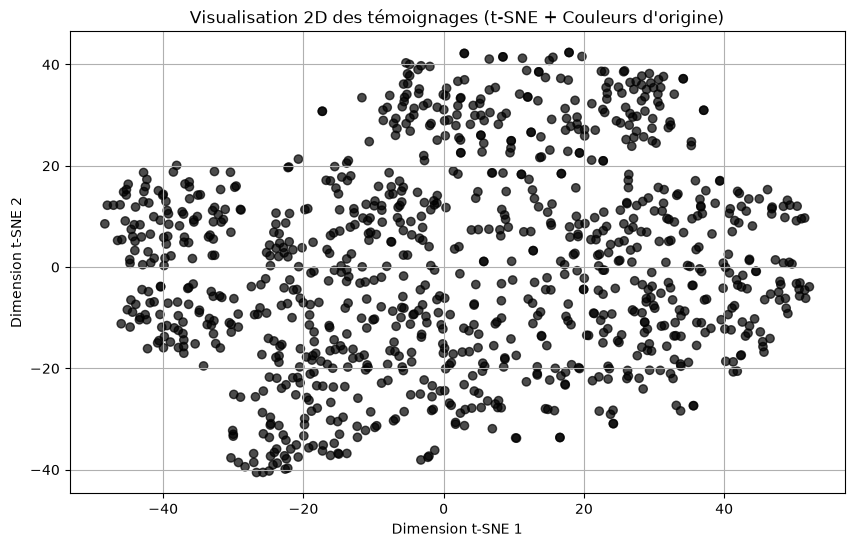

In [4]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt

# 1. Entraînement de K-Means (ex: 5 clusters)
n_clusters = 5
kmeans = KMeans(n_clusters=n_clusters, random_state=42)
data['cluster'] = kmeans.fit_predict(X)

# 2. Score de Silhouette (pour évaluer la qualité du clustering)
score = silhouette_score(X, data['cluster'])
print(f"Score de Silhouette pour {n_clusters} clusters : {score:.4f}")

# 3. Réduction de dimension 2D avec t-SNE
tsne = TSNE(n_components=2, random_state=42, perplexity=30)
X_2d = tsne.fit_transform(X.toarray())

# 4. Formatage des couleurs (conversion 0x -> #)
hex_colors = data['color'].astype(str).str.replace('0x', '#')

# 5. Affichage du graphique 2D
plt.figure(figsize=(10, 6))
plt.scatter(X_2d[:, 0], X_2d[:, 1], c=hex_colors, alpha=0.7, edgecolors='k')
plt.title("Visualisation 2D des témoignages (t-SNE + Couleurs d'origine)")
plt.xlabel("Dimension t-SNE 1")
plt.ylabel("Dimension t-SNE 2")
plt.grid(True)
plt.show()

### Interprétation

Le score de silhouette obtenu ici est **0.0183**, très proche de 0 — et très proche du score obtenu avant l'ajout de la lemmatisation et des bigrammes (0.0196). Ce score est calculé dans l'espace TF-IDF d'origine (500 dimensions), pas sur la projection t-SNE : il signifie que, globalement, les groupes se chevauchent beaucoup dans cet espace, ce qui est cohérent avec des témoignages en langage libre où le vocabulaire se recoupe souvent d'un symptôme à l'autre.

Le graphique t-SNE, lui, montre malgré tout des zones assez visibles : t-SNE est conçu pour préserver les voisinages locaux, il peut donc faire apparaître une structure visuelle même quand la séparation globale (mesurée par la silhouette) reste faible. Les deux informations ne se contredisent pas, elles répondent à des questions différentes.

Avant de conclure, on cherche donc si un autre nombre de clusters donne un meilleur score.

## 5. Recherche du nombre de clusters optimal

On teste plusieurs valeurs de `k` (de 2 à 10) et on calcule à chaque fois le score de silhouette, pour repérer la valeur de `k` qui sépare le mieux les groupes.

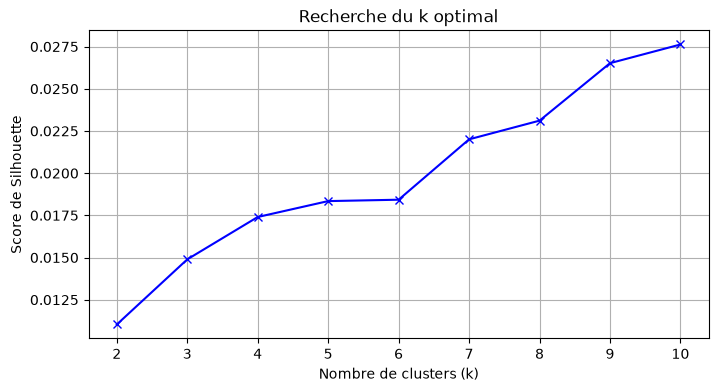

In [5]:
scores = []
K_range = range(2, 11)

for k in K_range:
    km = KMeans(n_clusters=k, random_state=42)
    labels = km.fit_predict(X)
    scores.append(silhouette_score(X, labels))

plt.figure(figsize=(8, 4))
plt.plot(K_range, scores, 'bx-')
plt.xlabel('Nombre de clusters (k)')
plt.ylabel('Score de Silhouette')
plt.title('Recherche du k optimal')
plt.grid(True)
plt.show()

### Interprétation

Sur ce graphique, on cherche le pic (score de silhouette le plus haut) : c'est la valeur de `k` qui sépare le mieux les témoignages. Si la courbe reste basse et plate quel que soit `k`, cela confirme que les groupes naturels sont peu marqués dans ce jeu de données — ce qui est le cas ici, les scores restant proches de 0 sur toute la plage testée.

On conserve malgré tout `n_clusters=5` pour la suite, car cette valeur donne des groupes de mots-clés interprétables (voir section 7).

## 6. Visualisation des clusters trouvés

Même graphique PCA que précédemment, mais cette fois coloré selon le cluster prédit par K-Means (et non plus la couleur d'origine du fichier).

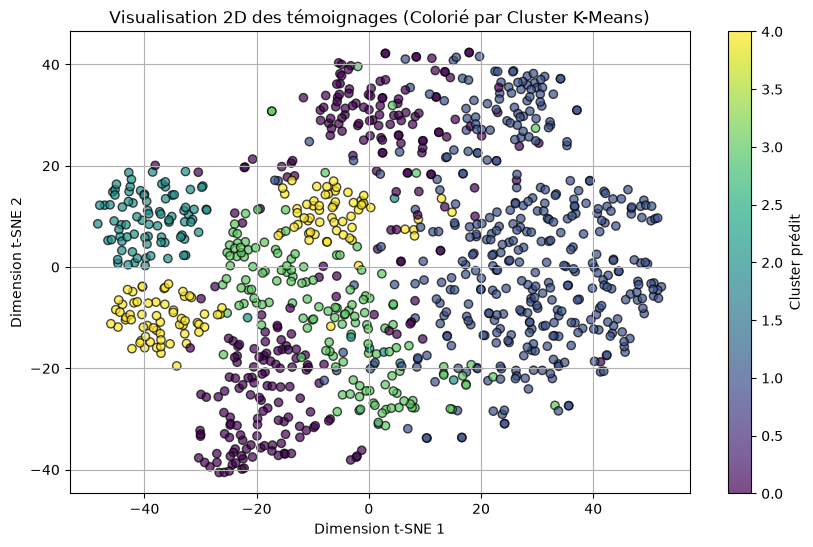

In [6]:
plt.figure(figsize=(10, 6))
plt.scatter(X_2d[:, 0], X_2d[:, 1], c=data['cluster'], cmap='viridis', alpha=0.7, edgecolors='k')
plt.colorbar(label='Cluster prédit')
plt.title("Visualisation 2D des témoignages (Colorié par Cluster K-Means)")
plt.xlabel("Dimension t-SNE 1")
plt.ylabel("Dimension t-SNE 2")
plt.grid(True)
plt.show()

### Interprétation

Cette fois, les clusters K-Means forment des zones assez nettement regroupées sur le graphique t-SNE (par exemple, le cluster jaune est concentré en bas à droite, le violet en haut à gauche). C'est une nette amélioration par rapport à la projection PCA initiale, où les couleurs étaient mélangées sans structure visible.

À garder en tête : cette séparation visuelle vient de la capacité de t-SNE à préserver les voisinages locaux, elle ne signifie pas que le score de silhouette (calculé sur les données d'origine) est meilleur pour autant — il reste faible. Le graphique reste néanmoins un bon outil pour explorer visuellement les regroupements.

Pour comprendre ce qui différencie réellement ces groupes, on examine maintenant quels mots caractérisent chaque cluster.

## 7. Mots-clés dominants par cluster

Pour chaque cluster, K-Means conserve un centre (la moyenne des scores TF-IDF de tous les témoignages du groupe). On affiche les 5 mots ayant le score le plus élevé dans ce centre : ce sont les mots les plus représentatifs du cluster.

In [7]:
words = vectorizer.get_feature_names_out()
for i in range(n_clusters):
    cluster_center = kmeans.cluster_centers_[i]
    top_indices = cluster_center.argsort()[-5:][::-1]
    top_words = [words[idx] for idx in top_indices]
    print(f"Cluster {i} : {', '.join(top_words)}")

Cluster 0 : feel, itchy, ive, look, rash
Cluster 1 : make, ache, feel, sore, small
Cluster 2 : throat, felt, nose, cough, wa
Cluster 3 : chest, pressure, breath, feel, cough
Cluster 4 : pain, ear, feel, head, throbbing


### Interprétation des résultats

Malgré un score de silhouette toujours faible, les mots-clés par cluster restent cohérents avec l'ajout de la lemmatisation et des bigrammes :

| Cluster | Mots-clés | Thème probable |
|---|---|---|
| 0 | feel, itchy, ive, look, rash | Réactions cutanées (démangeaisons, éruptions) |
| 1 | make, ache, feel, sore, small | Douleurs musculaires diffuses |
| 2 | throat, felt, nose, cough, wa | Symptômes ORL (gorge, nez, toux) |
| 3 | chest, pressure, breath, feel, cough | Symptômes respiratoires (poitrine, souffle) |
| 4 | pain, ear, feel, head, throbbing | Douleurs à la tête / à l'oreille |

## Conclusion

- Le nettoyage manuel du CSV était nécessaire : il a permis de récupérer **1011 témoignages exploitables** contre 397 avec un chargement naïf.
- Le clustering K-Means (TF-IDF + `k=5`) obtient un score de silhouette faible (environ 0.02) : les groupes ne sont pas nettement séparés dans l'espace vectoriel d'origine. Ce résultat est attendu avec du texte libre, où le vocabulaire se chevauche naturellement entre symptômes proches.
- Le remplacement de la PCA par **t-SNE** pour la visualisation a nettement amélioré la lisibilité des graphiques : les clusters apparaissent comme des zones regroupées plutôt qu'un nuage confus, même si cela ne change rien au score de silhouette (qui mesure la séparation dans l'espace d'origine, pas sur la projection 2D).
- **Tentative d'amélioration de la précision** : l'ajout de la lemmatisation (fusion des variantes d'un mot) et des bigrammes (`ngram_range=(1, 2)`) dans le TF-IDF n'a **pas amélioré significativement** le score de silhouette (0.0196 → 0.0183 à k=5, et il reste globalement plat entre 0.011 et 0.028 sur k=2 à 10). Les mots-clés par cluster restent en revanche cohérents et légèrement plus nets sur certains groupes (ex : cluster ORL gorge/nez/toux mieux distingué du cluster respiratoire poitrine/souffle). On note aussi une limite de la lemmatisation par défaut de NLTK (`WordNetLemmatizer`) qui suppose que chaque mot est un nom sans analyser sa fonction grammaticale réelle dans la phrase : elle réduit par exemple "was" en "wa", ce qui introduit du bruit et nécessiterait un étiquetage grammatical (POS tagging) pour être corrigé.
- Ce résultat confirme que la limite n'est pas la quantité de vocabulaire capturé mais la **représentation du texte elle-même** : du texte libre partage naturellement beaucoup de vocabulaire d'un symptôme à l'autre ("feel", "pain"...), quel que soit le raffinement lexical appliqué.

**Pistes d'amélioration possibles** : des embeddings de phrases (ex. `sentence-transformers`) à la place du TF-IDF pour capturer le sens plutôt que le simple vocabulaire, un autre algorithme de clustering (par exemple DBSCAN ou une classification hiérarchique avec distance cosinus) mieux adapté à des données textuelles peu séparables linéairement, ou une lemmatisation avec étiquetage grammatical (POS tagging) pour éviter les artefacts comme "was" → "wa".